**NB** : **Pour le retard de croissance (stunting)**

**Choix méthodologiques de cette version**
- Un seul modèle : la **régression logistique** (l'arbre de décision est retiré pour cette itération).
- Le découpage (train/test **et** validation croisée) se fait **par grappe**, jamais au hasard : les enfants d'une même grappe (donc d'un même ménage) ne sont jamais séparés entre entraînement et validation, pour éviter la fuite d'information.
- Métrique principale : **AUC ROC**, avec le rappel, la PR AUC, la log loss et la matrice de confusion.

**Plan** : Librairies - Données - Features / label - Split par grappe - Preprocessor - Baseline - Validation croisée par grappe - Modèle final - Évaluation (guide des métriques, AUC ROC, matrice de confusion)

# Librairies

### Lecture et visualisation des données

In [1]:
import pandas as pd              # manipulation des tableaux
import numpy as np               # calcul numérique
import matplotlib.pyplot as plt  # graphiques
import seaborn as sns            # graphiques statistiques

### Separation et validation

In [2]:
from sklearn.model_selection import (
    StratifiedGroupKFold, # decoupage PAR GRAPPE (une grappe n'est jamais coupee) en gardant les proportions de classes
    cross_validate,       # validation croisee avec plusieurs metriques + temps
    GridSearchCV,         # (reserve pour la suite) recherche des meilleurs hyperparametres
)

### Preparation des donnees

In [3]:
from sklearn.pipeline import Pipeline                                           # enchaine pretraitement + modele
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder  # Pour encodage
from sklearn.compose import ColumnTransformer                                   # un encodage different selon la colonne
from sklearn.base import clone                                                  # (reserve pour la suite) verification apres encodage

### Evaluation

In [4]:
from sklearn.metrics import (
    balanced_accuracy_score,  # moyenne du rappel des deux classes
    classification_report,    # precision / rappel / F1 par classe
    confusion_matrix,
    ConfusionMatrixDisplay,   # affichage de la matrice de confusion
    fbeta_score,              # (reserve pour la suite) F-beta, pour favoriser le rappel
    make_scorer,              # (reserve pour la suite) scorer personnalise
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,            # AUC ROC
    roc_curve,                # points de la courbe ROC
    log_loss,                 # qualite des probabilites
    average_precision_score,  # PR AUC
)

from sklearn.inspection import permutation_importance  # (reserve pour la suite) importance des variables

### Modele choisi

In [5]:
from sklearn.dummy import DummyClassifier             # modele de reference (baseline)
from sklearn.linear_model import LogisticRegression   # unique modele de cette version

In [6]:
# Fixer le random_state (reproductibilite)
RANDOM_STATE = 42

# Données

In [7]:
# Chargement des donnees nettoyees
df = pd.read_parquet('../data/clean/model_stunting.parquet')

print(f"Taille ; {df.shape}")

Taille ; (4864, 15)


In [8]:
# Apercu
df.head()

,age_mois,region,edu_mere,electricite,cuisiniere,toilettes,sexe_f,acte_naissance,eau_amelioree,animaux,stunt,grappe,menage,id_menage,ligne_enfant
0,33,Maritime,Primaire,Réseau,Feu ouvert,Chasse d'eau,1,1.0,0.0,0,0,1,7,1-7,5
1,41,Maritime,Primaire,Réseau,Combustible solide (cuisinière),Latrine améliorée,0,1.0,1.0,0,0,1,15,1-15,2
2,12,Maritime,Aucune,Réseau,Combustible solide (cuisinière),Non améliorée,1,0.0,1.0,0,0,1,18,1-18,6
3,22,Maritime,Aucune,Réseau,Combustible solide (cuisinière),Non améliorée,0,1.0,1.0,0,0,2,1,2-1,4
4,3,Maritime,Secondaire ou plus,Réseau,Combustible solide (cuisinière),Latrine améliorée,0,1.0,1.0,0,0,2,2,2-2,2


# Features / label

In [9]:
# Liste des colonnes
df.columns

Index(['age_mois', 'region', 'edu_mere', 'electricite', 'cuisiniere',
       'toilettes', 'sexe_f', 'acte_naissance', 'eau_amelioree', 'animaux',
       'stunt', 'grappe', 'menage', 'id_menage', 'ligne_enfant'],
      dtype='object')

In [10]:
# Colonnes qui ne doivent JAMAIS etre des features :
# - grappe, menage, id_menage, ligne_enfant : identifiants (grappe sert uniquement au decoupage)
# - stunt : la cible
NON_ENTREES = ["grappe", "menage", "id_menage", "ligne_enfant", 'stunt']

In [11]:
X = df.drop(columns=NON_ENTREES)  # Entrees (features)
y = df['stunt']                      # Sortie (label) : 1 = retard de croissance, 0 = non
groups = df['grappe']                # Groupe utilise pour le decoupage (jamais comme feature)

In [12]:
# Verification des features retenues
print(f"\nVérification : {X.columns.tolist()}")


Vérification : ['age_mois', 'region', 'edu_mere', 'electricite', 'cuisiniere', 'toilettes', 'sexe_f', 'acte_naissance', 'eau_amelioree', 'animaux']


In [13]:
# Valeurs de la cible (binaire)
y.unique()

array([0, 1], dtype=int8)

In [14]:
X.head()

,age_mois,region,edu_mere,electricite,cuisiniere,toilettes,sexe_f,acte_naissance,eau_amelioree,animaux
0,33,Maritime,Primaire,Réseau,Feu ouvert,Chasse d'eau,1,1.0,0.0,0
1,41,Maritime,Primaire,Réseau,Combustible solide (cuisinière),Latrine améliorée,0,1.0,1.0,0
2,12,Maritime,Aucune,Réseau,Combustible solide (cuisinière),Non améliorée,1,0.0,1.0,0
3,22,Maritime,Aucune,Réseau,Combustible solide (cuisinière),Non améliorée,0,1.0,1.0,0
4,3,Maritime,Secondaire ou plus,Réseau,Combustible solide (cuisinière),Latrine améliorée,0,1.0,1.0,0


In [15]:
# Verification : valeurs manquantes dans les features (la regression logistique n'en accepte aucune)
manquants = X.isna().sum()
print(manquants[manquants > 0] if manquants.any() else "Aucune valeur manquante dans X")

# Equilibre de la cible
print(f"\nProportion de retard de croissance (stunt=1) : {y.mean():.3f}")

Aucune valeur manquante dans X

Proportion de retard de croissance (stunt=1) : 0.244


# Train_test_split (par grappe)

On utilise `StratifiedGroupKFold` : chaque **grappe reste entière** dans un seul sous-ensemble (donc tous les enfants d'un même ménage restent ensemble) et les proportions de classes sont conservées au mieux. Un pli sur 5 sert de test (environ 20 %). Contrairement à un `train_test_split` aléatoire, cela évite que le modèle voie à l'entraînement des enfants très semblables à ceux du test (même ménage, même environnement), ce qui gonflerait les scores.

In [16]:
# Un pli sur 5 sert de test (~20 %), les 4 autres de train
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

# Verification 1 : aucune grappe partagee entre train et test
assert set(groups_train).isdisjoint(groups_test), "Fuite : une grappe est dans train ET test"

# Verification 2 : aucun menage partage entre train et test
assert set(df['id_menage'].iloc[train_idx]).isdisjoint(df['id_menage'].iloc[test_idx]), "Fuite : un menage est dans train ET test"

# Repartition
print(f"Train : {X_train.shape[0]} observations | {groups_train.nunique()} grappes")
print(f"Test  : {X_test.shape[0]} observations | {groups_test.nunique()} grappes")

print("\nProportions des classes (train) :")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())

print("\nProportions des classes (test) :")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())

Train : 3973 observations | 341 grappes
Test  : 891 observations | 78 grappes

Proportions des classes (train) :
stunt
0    0.755097
1    0.244903
Name: proportion, dtype: float64

Proportions des classes (test) :
stunt
0    0.760943
1    0.239057
Name: proportion, dtype: float64


# Preprocessor

In [17]:
# Controle des modalites de eau_amelioree
X['eau_amelioree'].unique()

array([0., 1.])

In [18]:
# Inventaire des colonnes par type (pour choisir l'encodage de chacune)
print("\n")
print(f"{30*'-'}Colonnes numériques{30*'-'}")
print("\n")
for c in X.select_dtypes(include='number').columns :
    print(f"{c}{10*' - '}{df[c].nunique()}")
    print()

print("\n")

print(f"{30*'-'}Colonnes non-numériques{30*'-'}")
print("\n")
for c in X.select_dtypes(include='object').columns :
    print(f"{c}{10*' - '}{df[c].unique()}{10*' - '}{df[c].nunique()}")
    print()



------------------------------Colonnes numériques------------------------------


age_mois -  -  -  -  -  -  -  -  -  - 60

sexe_f -  -  -  -  -  -  -  -  -  - 2

acte_naissance -  -  -  -  -  -  -  -  -  - 2

eau_amelioree -  -  -  -  -  -  -  -  -  - 2

animaux -  -  -  -  -  -  -  -  -  - 2



------------------------------Colonnes non-numériques------------------------------


region -  -  -  -  -  -  -  -  -  - ['Maritime' 'Plateaux' 'Centrale' 'Kara' 'Savanes' 'Lomé Commune'
 'Golfe Urbain'] -  -  -  -  -  -  -  -  -  - 7

edu_mere -  -  -  -  -  -  -  -  -  - ['Primaire' 'Aucune' 'Secondaire ou plus'] -  -  -  -  -  -  -  -  -  - 3

electricite -  -  -  -  -  -  -  -  -  - ['Réseau' 'Non' 'Hors réseau'] -  -  -  -  -  -  -  -  -  - 3

cuisiniere -  -  -  -  -  -  -  -  -  - ['Feu ouvert' 'Combustible solide (cuisinière)'
 'Électricité, gaz ou liquide' 'Pas de repas préparé'] -  -  -  -  -  -  -  -  -  - 4

toilettes -  -  -  -  -  -  -  -  -  - ["Chasse d'eau" 'Latrine amélior

**Rappel des ordres (du plus faible au plus fort), pour plus tard :**
- `edu_mere` : Aucune, Primaire, Secondaire ou plus
- `electricite` : Non, Hors réseau, Réseau
- `toilettes` : Aucune, Non améliorée, Latrine améliorée, Chasse d'eau
- `cuisiniere` : Pas de repas préparé, Feu ouvert, Combustible solide (cuisinière), Électricité, gaz ou liquide


**Rappel des binaires, pour plus tard :**
- `0` : non
- `1` : oui

In [19]:
# Listes de colonnes par type d'encodage
numeric_features = ['age_mois']

nominal_features = ['region']

ordinal_features = ['edu_mere', 'cuisiniere', 'electricite', 'toilettes']

binaires = ['sexe_f', 'acte_naissance', 'eau_amelioree', 'animaux']

# Ordre des modalites (du plus faible au plus fort), meme ordre que ordinal_features
edu_order = ['Aucune', 'Primaire', 'Secondaire ou plus']
cuisine_order = ['Pas de repas préparé', 'Feu ouvert', 'Combustible solide (cuisinière)', 'Électricité, gaz ou liquide']
elec_order = ['Non', 'Hors réseau', 'Réseau']
toilette_order = ['Aucune', 'Non améliorée', 'Latrine améliorée', 'Chasse d\'eau']

# Verification : chaque feature est dans exactement une liste (rien d'oublie, rien en double)
toutes = numeric_features + nominal_features + ordinal_features + binaires
assert sorted(toutes) == sorted(X.columns), f"Colonnes non couvertes ou en double : {set(X.columns) ^ set(toutes)}"

In [20]:
# Pretraitement : un encodage adapte a chaque type de variable
# (ajuste uniquement sur le train a chaque pli grace au Pipeline : pas de fuite)
preprocessor = ColumnTransformer(
    transformers=[
        # Numeriques : standardisation
        ("num", StandardScaler(), numeric_features),

        # Nominales : sparse_output=False obligatoire avec la sortie pandas
        ("nom", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), nominal_features),

        # Ordinales : encodage 0, 1, 2...
        ("ord", OrdinalEncoder(categories=[edu_order, cuisine_order, elec_order, toilette_order]), ordinal_features),

        # Binaires : passent tels quels
        ("bin", "passthrough", binaires),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

ColumnTransformer(transformers=[('num', StandardScaler(), ['age_mois']),
                                ('nom',
                                 OneHotEncoder(drop='if_binary',
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['region']),
                                ('ord',
                                 OrdinalEncoder(categories=[['Aucune',
                                                             'Primaire',
                                                             'Secondaire ou '
                                                             'plus'],
                                                            ['Pas de repas '
                                                             'préparé',
                                                             'Feu ouvert',
                                                             'Combustible '
                                                             'solide '
                                                             '(cuisinière)',
                                                             'Électricité, gaz '
                                                             'ou liquide'],
                                                            ['Non',
                                                             'Hors réseau',
                                                             'Réseau'],
                                                            ['Aucune',
                                                             'Non améliorée',
                                                             'Latrine '
                                                             'améliorée',
                                                             "Chasse d'eau"]]),
                                 ['edu_mere', 'cuisiniere', 'electricite',
                                  'toilettes']),
                                ('bin', 'passthrough',
                                 ['sexe_f', 'acte_naissance', 'eau_amelioree',
                                  'animaux'])],
                  verbose_feature_names_out=False)

# Modèle de référence (baseline)

Avant tout modèle, un point de comparaison minimal : un classifieur qui prédit toujours la **proportion de la classe** observée dans le train (`DummyClassifier(strategy="prior")`). Tout modèle sérieux doit faire nettement mieux. Repères de la baseline : AUC ROC = **0,5**, PR AUC = **proportion de retard** (environ 0,24), rappel = 0, log loss = valeur obtenue en prédisant toujours cette proportion.

In [21]:
def evaluer(y_true, y_pred, y_proba):
    """Calcule toutes les metriques d'un coup (classification binaire).
    y_pred  : classe predite (0/1, seuil 0.5)
    y_proba : probabilite predite de la classe 1 (retard de croissance)"""
    return {
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "auc_roc": roc_auc_score(y_true, y_proba),           # metrique principale
        "pr_auc": average_precision_score(y_true, y_proba),
        "log_loss": log_loss(y_true, y_proba),               # plus petit = mieux
    }


# Baseline : predit toujours la proportion de la classe du train
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

scores_baseline = evaluer(y_test, baseline.predict(X_test), baseline.predict_proba(X_test)[:, 1])
print("Baseline sur le test :")
pd.Series(scores_baseline, name="baseline").round(3).to_frame()

Baseline sur le test :


,baseline
recall,0.000
precision,0.000
f1,0.000
balanced_accuracy,0.500
auc_roc,0.500
pr_auc,0.239
log_loss,0.550


# Validation croisée par grappe

Validation croisée à 5 plis avec `StratifiedGroupKFold` : chaque grappe n'apparaît que dans **un seul pli de validation**. On passe `groups=` à `cross_validate`. On compare les scores **train** et **validation** pour repérer un éventuel surapprentissage. La régression logistique utilise `class_weight='balanced'` pour tenir compte du déséquilibre (environ 24 % de retard de croissance).

In [22]:
# Pipeline complet : pretraitement + regression logistique
pipe_lr = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'
    )),
])

# Validation croisee par grappe
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Controle du decoupage : aucune grappe ni menage partage entre train et validation
ids_menage_train = df['id_menage'].iloc[train_idx].to_numpy()
for k, (tr, va) in enumerate(cv.split(X_train, y_train, groups_train), start=1):
    assert set(groups_train.iloc[tr]).isdisjoint(groups_train.iloc[va]), f"Pli {k} : grappe partagee"
    assert set(ids_menage_train[tr]).isdisjoint(ids_menage_train[va]), f"Pli {k} : menage partage"
    print(f"Pli {k} : {len(tr)} train | {len(va)} validation | {groups_train.iloc[va].nunique()} grappes en validation")

# Dictionnaire des metriques
scoring = {
    'auc_roc': 'roc_auc',                    # metrique principale
    'recall': 'recall',
    'pr_auc': 'average_precision',
    'log_loss': 'neg_log_loss',              # sklearn renvoie l'oppose (negatif) : on inverse le signe plus bas
    'balanced_accuracy': 'balanced_accuracy',
}

scores = cross_validate(
    pipe_lr, X_train, y_train,
    groups=groups_train,       # decoupage par grappe
    cv=cv,
    scoring=scoring,
    return_train_score=True,   # pour comparer train et validation
)

# Tableau recapitulatif (moyenne et ecart-type sur les 5 plis)
signe = {m: (-1 if m == 'log_loss' else 1) for m in scoring}   # log_loss : on remet le signe positif
recap_cv = pd.DataFrame({
    m: {
        "train (moy)": signe[m] * scores[f"train_{m}"].mean(),
        "validation (moy)": signe[m] * scores[f"test_{m}"].mean(),
        "validation (ecart-type)": scores[f"test_{m}"].std(),
    } for m in scoring
}).T

print(f"\nTemps d'entrainement moyen par pli : {scores['fit_time'].mean():.2f}s\n")
recap_cv.round(3)

Pli 1 : 3208 train | 765 validation | 68 grappes en validation
Pli 2 : 3145 train | 828 validation | 71 grappes en validation
Pli 3 : 3192 train | 781 validation | 65 grappes en validation
Pli 4 : 3263 train | 710 validation | 65 grappes en validation
Pli 5 : 3084 train | 889 validation | 72 grappes en validation

Temps d'entrainement moyen par pli : 0.09s



,train (moy),validation (moy),validation (ecart-type)
auc_roc,0.648,0.635,0.014
recall,0.671,0.656,0.071
pr_auc,0.342,0.332,0.016
log_loss,0.659,0.660,0.018
balanced_accuracy,0.613,0.609,0.011


In [23]:
# AUC ROC par pli : permet de voir la stabilite du modele selon le decoupage
pd.Series(scores["test_auc_roc"], index=[f"pli {k}" for k in range(1, 6)], name="AUC ROC (validation)").round(3).to_frame().T

,pli 1,pli 2,pli 3,pli 4,pli 5
AUC ROC (validation),0.655,0.613,0.635,0.628,0.646


# Modèle final et prédictions

In [24]:
# Entrainement sur tout le train, puis predictions sur le test (jamais vu pendant la validation)
pipe_lr.fit(X_train, y_train)

y_pred = pipe_lr.predict(X_test)                # classe predite (seuil 0.5)
y_proba = pipe_lr.predict_proba(X_test)[:, 1]   # probabilite de retard de croissance

# Évaluation

### Guide des métriques : comment les interpréter

**Convention :** classe positive = **retard de croissance** (`stunt = 1`, environ 24 % des enfants). Toutes les métriques vont de 0 à 1 (plus c'est haut, mieux c'est) **sauf la log loss** (plus c'est bas, mieux c'est). On les lit **toujours par rapport à la baseline** et en regardant l'écart entre validation et train.

| Métrique | Question à laquelle elle répond | Valeur de la baseline | Piège à éviter |
|---|---|---|---|
| **Rappel** (recall) | Parmi les enfants réellement en retard de croissance, quelle part le modèle repère-t-il ? | 0 (baseline qui ne prédit jamais "retard") | Facile à gonfler en prédisant "retard" pour presque tout le monde : toujours le lire avec la précision |
| **Précision** | Quand le modèle annonce "retard", a-t-il raison ? | environ la proportion de retard (0,24) si prédiction au hasard | Une précision haute peut cacher un rappel faible (modèle trop prudent) |
| **F1** | Compromis (moyenne harmonique) entre précision et rappel | 0 | Donne le même poids à la précision et au rappel, ce qui n'est pas toujours souhaitable |
| **Accuracy équilibrée** | Le modèle retrouve-t-il bien **les deux** classes ? (moyenne du rappel de chaque classe) | 0,5 | Ne dit pas si les erreurs viennent de faux positifs ou de faux négatifs |
| **AUC ROC** | Le modèle **classe-t-il** bien les enfants ? Probabilité qu'un enfant en retard reçoive une probabilité plus haute qu'un enfant non en retard | **0,5** | Ne dépend d'aucun seuil, mais ne dit rien sur la justesse des probabilités ; peut paraître flatteuse quand la classe positive est minoritaire |
| **PR AUC** (average precision) | Même question que l'AUC ROC, mais centrée sur la classe positive (compromis précision / rappel sur tous les seuils) | la **proportion de retard** (0,24), pas 0,5 | Sa baseline dépend de la proportion de positifs : toujours la comparer à cette valeur |
| **Log loss** | Les **probabilités** sont-elles justes ? Elle pénalise fortement les erreurs commises avec une grande confiance | log loss obtenue en prédisant toujours la proportion de retard (environ 0,56 pour 24 %) | Seule métrique "plus petit = mieux" ; dans `cross_validate`, sklearn renvoie son **opposé** (`neg_log_loss`) |

**Lecture de l'AUC ROC (repères indicatifs, à adapter au contexte)**
- 0,5 : aucun pouvoir de discrimination (hasard) ; moins de 0,5 : le modèle se trompe de sens
- 0,5 à 0,7 : faible | 0,7 à 0,8 : acceptable | 0,8 à 0,9 : bon | au-dessus de 0,9 : excellent
- Quand la classe positive est minoritaire, vérifier aussi la **PR AUC** : elle est plus exigeante.

**Lecture de la matrice de confusion (2 x 2)**
- **Lignes = vraie classe, colonnes = classe prédite** (convention scikit-learn) : `[[VN, FP], [FN, VP]]`.
- **VP** (vrai positif) : enfant en retard, détecté. **FN** (faux négatif) : enfant en retard, **non détecté** (l'erreur la plus coûteuse en dépistage). **FP** (faux positif) : alerte inutile. **VN** : enfant non en retard, correctement écarté.
- Version **normalisée par ligne** : la case VP devient le **rappel**, la case VN le rappel de la classe 0.
- Les prédictions utilisent le seuil par défaut de **0,5**. Changer le seuil déplace le compromis FN / FP, mais **ne change pas l'AUC ROC**.

**Point d'attention : `class_weight='balanced'` et probabilités**
Ce réglage aide à repérer la classe minoritaire (meilleur rappel), mais il **gonfle les probabilités** de la classe positive : elles ne sont plus de vraies fréquences. L'AUC ROC et la PR AUC ne sont pas affectées (elles ne regardent que le classement), mais la **log loss** se dégrade. Si les probabilités doivent servir telles quelles (par exemple pour définir des niveaux de risque), il faudra les **calibrer**.

**Comment juger les résultats de ce notebook**
1. Comparer le modèle à la **baseline** : AUC ROC nettement au-dessus de 0,5, PR AUC nettement au-dessus de 0,24.
2. Comparer **train et validation** : un grand écart signale un surapprentissage.
3. Regarder l'**écart-type entre plis** : s'il est élevé, le score dépend beaucoup du découpage.
4. Comparer **validation croisée et test** : des valeurs proches indiquent un modèle stable.
5. Le découpage **par grappe** donne des scores plus honnêtes (souvent un peu plus bas) qu'un découpage aléatoire, car le modèle ne peut pas profiter d'enfants du même ménage vus à l'entraînement.

### Métriques sur le jeu de test

In [25]:
# Regression logistique vs baseline sur le test
scores_lr = evaluer(y_test, y_pred, y_proba)

comparaison = pd.DataFrame({"baseline": scores_baseline, "regression logistique": scores_lr})
comparaison["difference"] = comparaison["regression logistique"] - comparaison["baseline"]
comparaison.round(3)

,baseline,regression logistique,difference
recall,0.000,0.615,0.615
precision,0.000,0.332,0.332
f1,0.000,0.432,0.432
balanced_accuracy,0.500,0.614,0.114
auc_roc,0.500,0.662,0.162
pr_auc,0.239,0.363,0.124
log_loss,0.550,0.644,0.094


### Courbe ROC

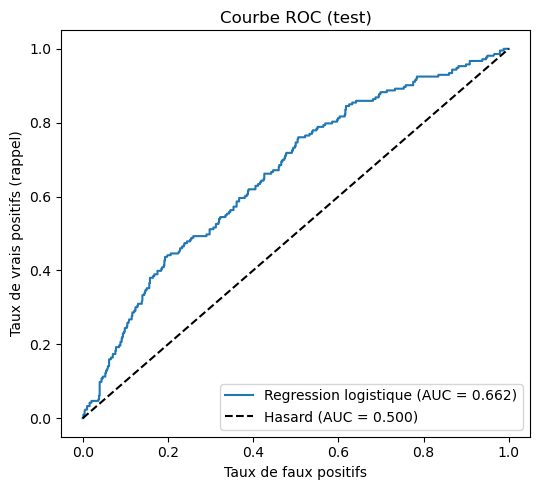

In [26]:
# Courbe ROC : taux de vrais positifs en fonction du taux de faux positifs, pour tous les seuils
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"Regression logistique (AUC = {scores_lr['auc_roc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Hasard (AUC = 0.500)")   # diagonale = modele sans pouvoir predictif
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.title("Courbe ROC (test)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Rapport par classe

In [27]:
# Precision, rappel, F1 et effectif (support) pour chaque classe
print(classification_report(y_test, y_pred, target_names=["Pas de retard (0)", "Retard de croissance (1)"], zero_division=0))

                          precision    recall  f1-score   support

       Pas de retard (0)       0.84      0.61      0.71       678
Retard de croissance (1)       0.33      0.62      0.43       213

                accuracy                           0.61       891
               macro avg       0.58      0.61      0.57       891
            weighted avg       0.71      0.61      0.64       891



### Matrice de confusion

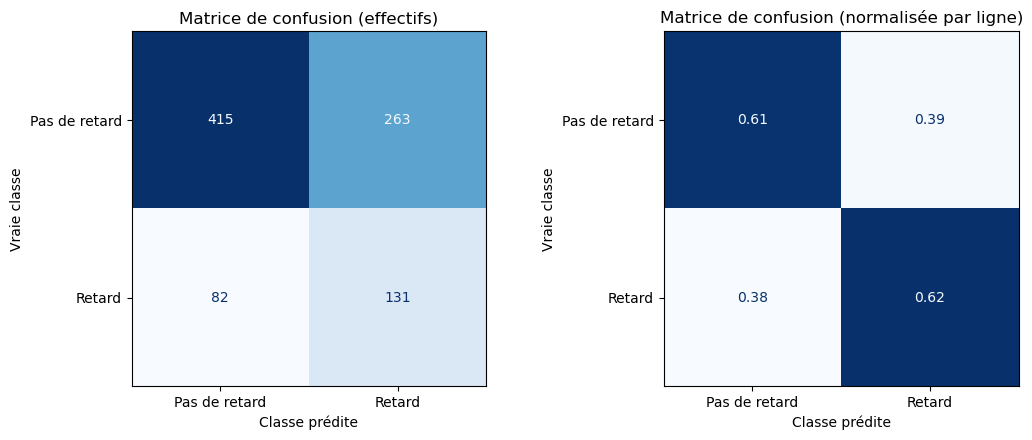

VP (retard detecte) = 131 | FN (retard manque) = 82 | FP (fausse alerte) = 263 | VN = 415


In [28]:
# Gauche : effectifs bruts | Droite : normalisee par ligne (la diagonale = rappel de chaque classe)
noms = ["Pas de retard", "Retard"]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_norm = confusion_matrix(y_test, y_pred, labels=[0, 1], normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(cm, display_labels=noms).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matrice de confusion (effectifs)")

ConfusionMatrixDisplay(cm_norm, display_labels=noms).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Matrice de confusion (normalisée par ligne)")

for ax in axes:
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Vraie classe")

plt.tight_layout()
plt.show()

# Lecture rapide des 4 cases
vn, fp, fn, vp = cm.ravel()
print(f"VP (retard detecte) = {vp} | FN (retard manque) = {fn} | FP (fausse alerte) = {fp} | VN = {vn}")

### Synthèse
- Les résultats (validation croisée et test) se lisent avec le guide des métriques ci-dessus.
- Suite possible : ajouter d'autres modèles dans le même cadre (même `cv`, même `scoring`, mêmes groupes), calibrer les probabilités, régler le seuil de décision, puis `permutation_importance` pour l'interprétation.